# 01c — Advanced EDA Research Questions

## Scope

This companion notebook contains the hypothesis-driven analyses moved from the initial EDA so that `01_eda.ipynb` remains concise and grading-aligned. It investigates target-label ambiguity, per-class feature separation, feature redundancy, laboratory shortcuts, near-duplicate split leakage, and cross-year distribution drift.

The findings support evaluation design and deployment-risk assessment; they are not baseline model results. Run this notebook from the project root after the source data have been downloaded.


## Data setup

The notebook loads CICIDS2017, applies the same target and cleaning policy used by the modeling workflow, and loads or creates the cached stratified CSE-CIC-IDS2018 sample. Keeping preparation inside this notebook makes Q1–Q6 independently reproducible.


In [1]:
import glob, os, time, warnings, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 120)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'grid.color': '#e6e6e3', 'axes.edgecolor': '#9a9993',
                     'axes.titleweight': 'bold', 'figure.dpi': 100})

BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#9a9993'
SEQ = 'Blues'
ROOT = './Data/archive'
D17, D18 = f'{ROOT}/CICIDS2017_improved', f'{ROOT}/CSECICIDS2018_improved'
SAMPLE18 = './Data/sample_2018_stratified.csv.gz'
SEED = 0
ID_COLS = ['id', 'Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Timestamp', 'Attempted Category']
ENV_FEATURES = ['Dst Port', 'FWD Init Win Bytes', 'Bwd Init Win Bytes', 'Fwd Seg Size Min', 'Protocol']

def signed_log(a):
    return np.sign(a) * np.log1p(np.abs(a))

/Users/ranga/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/8p/7ywd43m12fz07p58l3312vqh0000gn/T/matplotlib-_xb86xlr because there was an issue with the default path (/Users/ranga/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/ranga/.cache/fontconfig
	/Users/ranga/.fontconfig


Matplotlib is building the font cache; this may take a moment.


In [2]:
# Get the column names for the 2017 and 2018 datasets and check if they have the same schema

cols17 = pd.read_csv(glob.glob(f'{D17}/*.csv')[0], nrows=5).columns
cols18 = pd.read_csv(glob.glob(f'{D18}/*.csv')[0], nrows=5).columns
print(len(cols17), 'columns; same schema:', list(cols17) == list(cols18))
print(list(cols17))

91 columns; same schema: True
['id', 'Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd RST Flags', 'Bwd RST Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', '

In [3]:

# Read all CSV files from the 2017 dataset, add a 'day' column based on the file name, and concatenate them into a single DataFrame. Then, perform some basic data exploration and checks.
df = pd.concat([pd.read_csv(f).assign(day=os.path.basename(f)[:-4]) for f in sorted(glob.glob(f'{D17}/*.csv'))], ignore_index=True)


num = df.select_dtypes('number')
print('shape', df.shape, '| memory %.2f GB' % (df.memory_usage().sum()/1e9))
print('non-numeric columns:', list(df.select_dtypes('object').columns))
print('missing values:', df.isna().sum()[lambda s: s>0].to_dict())
print('infinite values:', np.isinf(num).sum()[lambda s: s>0].to_dict())
print('constant columns:', [c for c in num if num[c].nunique() <= 1])
# The following line checks for duplicate rows in the DataFrame, ignoring the specified columns (id, Flow ID, Timestamp, Src Port). 
# It drops these columns and then checks for duplicates in the remaining columns. The sum of duplicated rows is printed.
ids = ['id','Flow ID','Timestamp','Src Port']
print('duplicate rows (ignoring id/flow id/timestamp/src port): %d' % df.drop(columns=ids).duplicated().sum())

shape (2099976, 92) | memory 1.55 GB
non-numeric columns: ['Flow ID', 'Src IP', 'Dst IP', 'Timestamp', 'Label', 'day']


missing values: {}
infinite values: {'Flow Bytes/s': 5, 'Flow Packets/s': 5}


constant columns: []


duplicate rows (ignoring id/flow id/timestamp/src port): 138244


In [4]:

df['ts'] = pd.to_datetime(df['Timestamp'], errors='coerce')

# mapping the Label column to a binary 'is_attack' column, where attacks are marked as True and benign traffic is marked as False.
# Any lable with pattern ' - Attempted' is also considered benign. 
# Then, several new derived features are created based on existing columns, such as total packets, total payload bytes, duration in seconds, bytes per packet, packet direction ratio, and the hour of the timestamp. 
# Finally, a summary of the engineered features is displayed.
df['is_attack'] = ~df['Label'].eq('BENIGN') & ~df['Label'].str.endswith(' - Attempted')
df['total_packets_derived'] = df['Total Fwd Packet'] + df['Total Bwd packets']
df['total_payload_bytes_derived'] = df['Total Length of Fwd Packet'] + df['Total Length of Bwd Packet']

df['duration_seconds_derived'] = df['Flow Duration'] / 1_000_000 # microseconds to seconds
# Average bytes per packet is calculated by dividing the total payload bytes by the total number of packets
df['bytes_per_packet_derived'] = np.where(
    df['total_packets_derived'] > 0,
    df['total_payload_bytes_derived'] / df['total_packets_derived'],
    np.nan,
)

df['packet_direction_ratio_derived'] = (
    (df['Total Fwd Packet'] + 1) / (df['Total Bwd packets'] + 1)
)
df['hour_derived'] = df['ts'].dt.hour

engineered = [
    'total_packets_derived', 'total_payload_bytes_derived',
    'duration_seconds_derived', 'bytes_per_packet_derived',
    'packet_direction_ratio_derived', 'hour_derived'
]
display(df[engineered].describe(percentiles=[.01, .5, .99]).T.round(3))
num = df.select_dtypes('number')


,count,mean,std,min,1%,50%,99%,max
total_packets_derived,2099976.0,26.729,2027.899,2.000,2.000,4.000,137.000,5.116810e+05
total_payload_bytes_derived,2099976.0,22490.270,2627664.427,0.000,0.000,318.000,105562.000,6.554951e+08
duration_seconds_derived,2099976.0,12.440,31.030,0.000,0.000,0.062,118.104,1.200000e+02
bytes_per_packet_derived,2099976.0,212.022,293.502,0.000,0.000,81.000,1055.909,2.125667e+03
packet_direction_ratio_derived,2099976.0,1.325,4.570,0.022,0.667,1.000,3.000,7.420000e+02
hour_derived,2099976.0,15.540,2.453,11.000,12.000,16.000,19.000,2.000000e+01


## Preparation 1. Shared cleaned analysis tables

**Why we are doing this.** A consistent target definition, feature list, finite-value policy, constant-feature rule, and duplicate policy are applied before advanced comparisons.

**Business relevance.** Shared preparation ensures that later differences reflect traffic and model behavior rather than inconsistent preprocessing, making the baseline and cross-year results defensible.

The following preparation is performed once for all extended EDA sections. It uses the same label, leakage-column, infinity, constant-feature, and duplicate policies as the modeling notebooks.


In [5]:
raw17 = df
original_columns = list(cols17)
feature_candidates = [c for c in original_columns if c not in ID_COLS + ['Label']]
X_all = df[feature_candidates].replace([np.inf, -np.inf], np.nan)
FILL_MAX = X_all.max()
X_all = X_all.fillna(FILL_MAX)
constant = [c for c in feature_candidates if X_all[c].nunique() <= 1]
FEATURES = [c for c in feature_candidates if c not in constant]

df['attempted'] = df['Label'].str.endswith(' - Attempted')
df['y'] = df['Label'].where(~df['attempted'], 'BENIGN')
dup = pd.concat([X_all[FEATURES], df['y']], axis=1).duplicated()
d17 = pd.concat([
    X_all.loc[~dup, FEATURES],
    df.loc[~dup, ['Label', 'y', 'attempted', 'ts', 'id', 'day']],
], axis=1).reset_index(drop=True)

print(f'Model features: {len(FEATURES)} | constant columns removed: {constant}')
print(f'Duplicate feature/label rows removed: {dup.sum():,} | rows retained: {len(d17):,}')

Model features: 83 | constant columns removed: []
Duplicate feature/label rows removed: 258,629 | rows retained: 1,841,347


### Preparation 1 takeaway

The shared tables apply the same effective-attack definition and model-aligned preprocessing to both years. Identifiers and schedule fields are separated from predictors, constant and duplicate records are controlled, and compatible features are prepared for fair comparisons.


## Preparation 2. Build or load the stratified 2018 sample

**Why we are doing this.** A cached per-label sample makes distribution-heavy cross-year analysis practical while retaining enough observations from rare attack classes.

**Business relevance.** This reduces repeated processing cost and allows rare attacks to be inspected, while exact streamed counts remain the source for prevalence and operational-volume conclusions.

The full 2018 data are approximately 35 GB. A uniform per-label sample is cached for distribution comparisons. Its class proportions are not population estimates; exact population counts were reported above.


In [6]:
use = [c for c in original_columns if c not in ('Flow ID', 'Src IP', 'Dst IP')]
dtypes = {c: 'int64' for c in ('id', 'Src Port', 'Dst Port', 'Protocol', 'Attempted Category')}
if not os.path.exists(SAMPLE18):
    K_ATT, K_BEN = 20_000, 200_000
    rng = np.random.default_rng(SEED)
    keep = {}
    for f in sorted(glob.glob(f'{D18}/*.csv')):
        for ch in pd.read_csv(f, usecols=use, dtype=dtypes, chunksize=150_000):
            ch['_k'] = rng.random(len(ch))
            for lab, group in ch.groupby('Label'):
                k = K_BEN if lab == 'BENIGN' else K_ATT
                group = group if lab not in keep else pd.concat([keep[lab], group])
                keep[lab] = group.nsmallest(k, '_k') if len(group) > k else group
    pd.concat(keep.values()).drop(columns='_k').to_csv(SAMPLE18, index=False, compression='gzip')

s18 = pd.read_csv(SAMPLE18)
s18['attempted'] = s18['Label'].str.endswith(' - Attempted')
X18 = s18[FEATURES].replace([np.inf, -np.inf], np.nan).fillna(FILL_MAX)
s18[FEATURES] = X18
real18 = pd.read_csv('label_counts_2018.csv').groupby('Label').flows.sum()
sample_counts = pd.DataFrame({'sample flows': s18['Label'].value_counts(),
                              'full-data flows': real18}).fillna(0).astype(int)
sample_counts['sampling rate'] = sample_counts['sample flows'] / sample_counts['full-data flows']
print(f'2018 sample: {len(s18):,} flows and {s18.Label.nunique()} labels')
display(sample_counts.sort_values('full-data flows', ascending=False))

2018 sample: 378,952 flows and 25 labels


,sample flows,full-data flows,sampling rate
Label,,,
BENIGN,200000,59353486,0.003370
DoS Hulk,20000,1803160,0.011092
DDoS-HOIC,20000,1082293,0.018479
FTP-BruteForce - Attempted,20000,298874,0.066918
DDoS-LOIC-HTTP,20000,289328,0.069126
Botnet Ares,20000,142921,0.139937
SSH-BruteForce,20000,94197,0.212321
Infiltration - NMAP Portscan,20000,89374,0.223779
DoS GoldenEye,20000,22560,0.886525


### Preparation 2 takeaway

The cached 2018 sample contains many observations from every label so rare-class distributions can be compared without repeatedly scanning 36 GB. Because it is deliberately stratified, it supports within-label EDA but must not be used to estimate natural class prevalence or overall production accuracy.


## Q1. Do `- Attempted` flows look like benign traffic?

**Why we are doing this.** Attempted attacks are compared with benign and effective attacks to test whether folding them into the benign target creates label noise.

**Business relevance.** The labeling policy directly changes false-alarm and recall behavior. Understanding attempted flows supports a defensible definition of what the detector is expected to flag.

Labels ending in `- Attempted` mark connections that an attack tool opened but that delivered no effective malicious payload: for example, a SYN to a closed port, or a request sent after the server had already gone down. Notebook 02 folds them into `BENIGN`. If they look like attack traffic instead, that choice puts attack-shaped flows into the benign class and creates label noise the models must absorb.

The first table shows how much traffic the policy relabels in each year.


In [7]:
lab17 = raw17['Label'].value_counts()
def attempted_summary(counts, year):
    att = counts[counts.index.str.endswith(' - Attempted')]
    eff = counts[(counts.index != 'BENIGN') & ~counts.index.str.endswith(' - Attempted')]
    return pd.Series({'year': year, 'attempted flows': att.sum(), 'effective attack flows': eff.sum(),
                      'attempted / (attempted + effective)': round(att.sum() / (att.sum() + eff.sum()), 4),
                      'largest attempted label': f'{att.idxmax()} ({att.max():,})'})
display(pd.DataFrame([attempted_summary(lab17, 2017), attempted_summary(real18, 2018)]).set_index('year'))

,attempted flows,effective attack flows,attempted / (attempted + effective),largest attempted label
year,,,,
2017,11979,505431,0.0232,"Botnet - Attempted (4,067)"
2018,306237,3535422,0.0797,"FTP-BruteForce - Attempted (298,874)"


Next, the three groups are compared directly on features that describe connection shape: Benign, Attempted (relabelled as benign), and Effective attack. A two-sample Kolmogorov–Smirnov (KS) statistic measures how different two distributions are, from 0 (identical) to 1 (no overlap). For each feature we ask whether the Attempted distribution is closer to Benign or to Effective attack.

In [8]:
grp17 = np.where(raw17['attempted'], 'Attempted', np.where(raw17['y'].eq('BENIGN'), 'Benign', 'Effective attack'))
key = ['Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet',
       'Total Length of Bwd Packet', 'Flow Packets/s', 'FWD Init Win Bytes', 'Bwd Init Win Bytes',
       'SYN Flag Count', 'RST Flag Count', 'Fwd Seg Size Min']
med = X_all[key].groupby(grp17).median().T[['Benign', 'Attempted', 'Effective attack']]
display(med.round(1))

rng = np.random.default_rng(SEED)
pick = lambda name, n: X_all.loc[grp17 == name, FEATURES].sample(min(n, (grp17 == name).sum()), random_state=SEED)
ben_s, att_s, eff_s = pick('Benign', 50_000), pick('Attempted', 50_000), pick('Effective attack', 50_000)
ks_att = pd.DataFrame({'KS(attempted, benign)': [ks_2samp(att_s[f], ben_s[f]).statistic for f in FEATURES],
                       'KS(attempted, attack)': [ks_2samp(att_s[f], eff_s[f]).statistic for f in FEATURES]}, index=FEATURES)
closer = (ks_att['KS(attempted, attack)'] < ks_att['KS(attempted, benign)'])
print(f'Attempted flows are closer to effective attacks than to benign flows on {closer.sum()} of {len(FEATURES)} features.')
print('Median KS distance: to benign %.3f | to attack %.3f' % tuple(ks_att.median()))

,Benign,Attempted,Effective attack
Flow Duration,62890.0,3002878.0,37999.0
Total Fwd Packet,2.0,3.0,7.0
Total Bwd packets,2.0,1.0,4.0
Total Length of Fwd Packet,86.0,0.0,20.0
Total Length of Bwd Packet,214.0,0.0,11595.0
Flow Packets/s,64.3,1.1,363.6
FWD Init Win Bytes,0.0,29200.0,29200.0
Bwd Init Win Bytes,0.0,0.0,229.0
SYN Flag Count,0.0,2.0,2.0
RST Flag Count,0.0,0.0,1.0


Attempted flows are closer to effective attacks than to benign flows on 43 of 83 features.
Median KS distance: to benign 0.375 | to attack 0.390


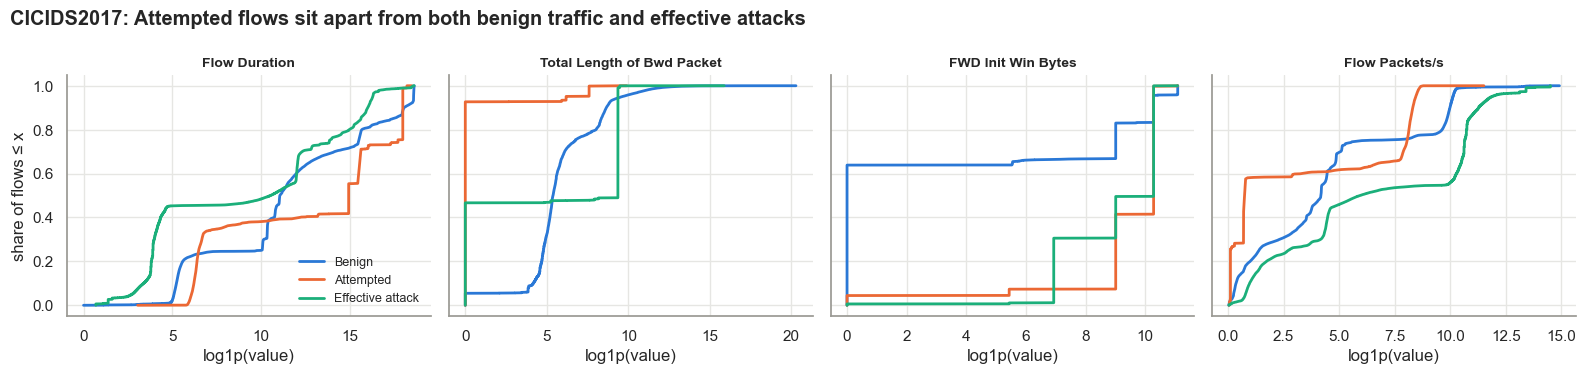

In [9]:
show = ['Flow Duration', 'Total Length of Bwd Packet', 'FWD Init Win Bytes', 'Flow Packets/s']
colors = {'Benign': BLUE, 'Attempted': ORANGE, 'Effective attack': AQUA}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, f in zip(axes, show):
    for name, s in [('Benign', ben_s), ('Attempted', att_s), ('Effective attack', eff_s)]:
        v = np.sort(signed_log(s[f].values))
        ax.plot(v, np.arange(1, len(v) + 1) / len(v), lw=2, color=colors[name], label=name)
    ax.set_title(f, fontsize=10); ax.set_xlabel('log1p(value)')
axes[0].set_ylabel('share of flows ≤ x')
axes[0].legend(frameon=False, loc='lower right', fontsize=9)
fig.suptitle('CICIDS2017: Attempted flows sit apart from both benign traffic and effective attacks', fontweight='bold', x=0.01, ha='left')
plt.tight_layout(); plt.show()

### Q1 takeaway

**Q1 finding.** Attempted flows do not look like ordinary benign traffic, but they do not look like effective attacks either. They are about equally distant from both: the median KS distance is 0.375 to benign and 0.390 to attack, and they are closer to attacks on 43 of 83 features. They carry the attacker's fingerprint: the same destination ports, the attack hosts' TCP initial window (29,200) and SYN flags. But they carry no payload and often hang for seconds. Q7 below shows the practical consequence: models trained on 2017 flag **75–89%** of attempted flows as attacks even though they are labelled benign. Folding them into `BENIGN` is defensible for a detector of *successful* attacks, but it creates a block of attack-shaped "benign" rows. That is a bigger issue in 2018, where all 298,874 FTP brute-force flows are `- Attempted`. Module 24 should compare the current policy with two alternatives: dropping these rows, or giving them their own class.


## Q2. Which features separate each attack class from benign traffic?

**Why we are doing this.** Per-class KS statistics identify which individual feature distributions differ most from benign traffic.

**Business relevance.** The analysis reveals which attacks are intrinsically easier to distinguish, where rare-class recall may be difficult, and which measurements deserve validation in the baseline.

For every attack class, each feature's distribution is compared with benign traffic using the KS statistic, on samples of up to 20,000 flows per class and 50,000 benign flows. The heatmap shows the 20 features with the highest average separation.


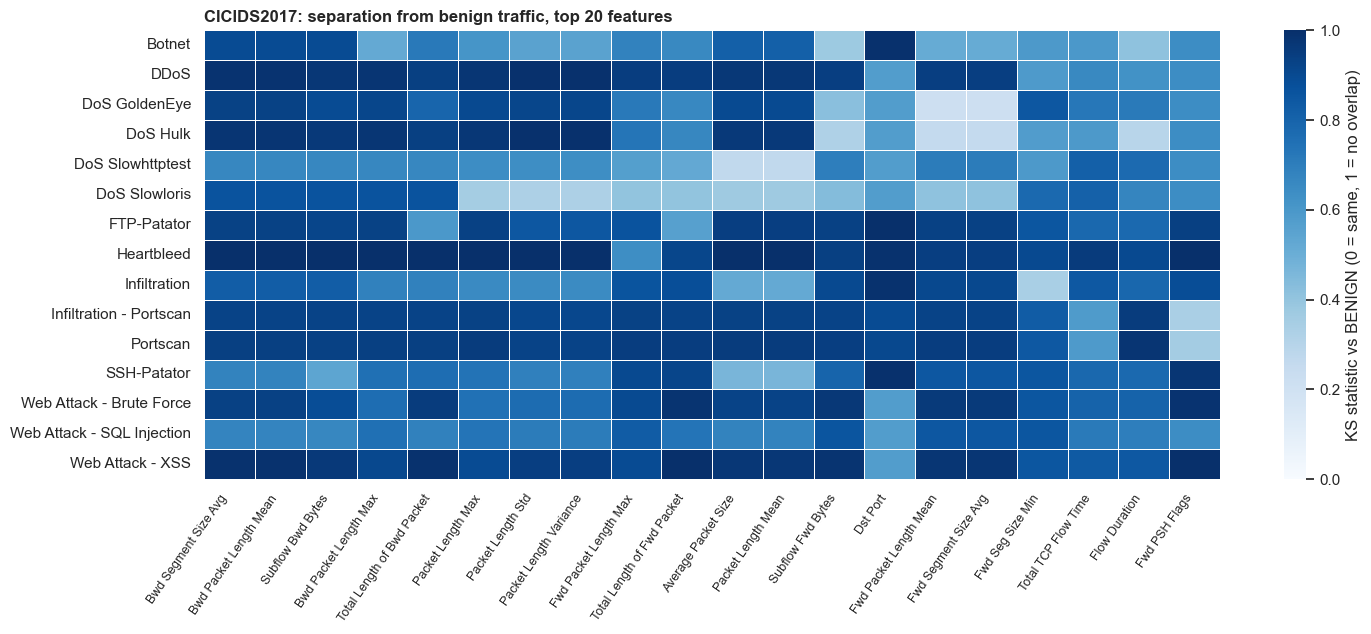

,best feature,best KS,features with KS ≥ 0.8
DoS Slowloris,Total Length of Bwd Packet,0.867,7
Web Attack - SQL Injection,Fwd Packet Length Std,0.881,7
DoS Slowhttptest,Fwd IAT Std,0.896,13
Infiltration - Portscan,Flow IAT Max,0.950,23
DoS GoldenEye,Bwd Packet Length Std,0.967,12
Portscan,Flow Duration,0.978,35
Web Attack - Brute Force,Fwd PSH Flags,0.985,30
Infiltration,Dst Port,0.989,18
SSH-Patator,Dst Port,0.993,18
Botnet,Dst Port,0.994,6


In [10]:
import gc
del X_all, grp17, df, num; gc.collect()   # Q1 is done with the raw table; free memory for the rest of the notebook

ben_ref = d17.loc[d17['y'].eq('BENIGN'), FEATURES].sample(50_000, random_state=SEED)
attack_classes = sorted(c for c in d17['y'].unique() if c != 'BENIGN')
ks = {}
for c in attack_classes:
    a = d17.loc[d17['y'].eq(c), FEATURES]
    a = a.sample(min(len(a), 20_000), random_state=SEED)
    ks[c] = {f: ks_2samp(ben_ref[f], a[f]).statistic for f in FEATURES}
ks = pd.DataFrame(ks).T          # rows = attack class, columns = feature
top20 = ks.mean().sort_values(ascending=False).head(20).index

fig, ax = plt.subplots(figsize=(15, 6.5))
sns.heatmap(ks[top20], cmap=SEQ, vmin=0, vmax=1, linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'KS statistic vs BENIGN (0 = same, 1 = no overlap)'}, ax=ax)
ax.set_title('CICIDS2017: separation from benign traffic, top 20 features', loc='left')
ax.set_xlabel(''); ax.set_ylabel('')
plt.xticks(rotation=55, ha='right', fontsize=9); plt.tight_layout(); plt.show()

summary_ks = pd.DataFrame({'best feature': ks.idxmax(axis=1), 'best KS': ks.max(axis=1).round(3),
                           'features with KS ≥ 0.8': (ks >= 0.8).sum(axis=1)}).sort_values('best KS')
summary_ks

### Q2 takeaway

**Q2 finding.** Every attack class has at least one feature with a KS statistic of 0.87 or more against benign traffic, and 12 of the 15 classes reach 0.95 or more. The strongest general separators are backward (server-to-client) payload sizes, such as `Bwd Packet Length Mean`, because each attack elicits a characteristic server response. For four classes (FTP-Patator, SSH-Patator, Botnet, and Infiltration), the single most separating feature is the destination port. The lowest best-feature separation is for DoS Slowloris (0.87), SQL Injection (0.88), and DoS Slowhttptest (0.90). These are also among the classes whose F1 is least stable in notebooks 02 and 03.


## Q3. How redundant is the feature set?

**Why we are doing this.** Hierarchical clustering groups features that carry nearly the same rank information under heavy skew.

**Business relevance.** Reducing redundant measurements can lower runtime, stabilize Logistic Regression coefficients, and make security explanations easier to trust.

Features are grouped by hierarchical clustering on `1 − |Spearman ρ|`, computed on a 100,000-flow sample. Spearman correlation is used because the features are heavily skewed. Features joined below a distance of 0.1 have |ρ| ≥ 0.9 and carry nearly the same ranking information.


1 pairs of features are exactly identical in the sample, e.g. [('Fwd URG Flags', 'URG Flag Count')]


,feature groups
distance threshold (1 − |ρ|),
0.0001,77
0.0500,49
0.1000,37
0.2000,27
0.3000,22


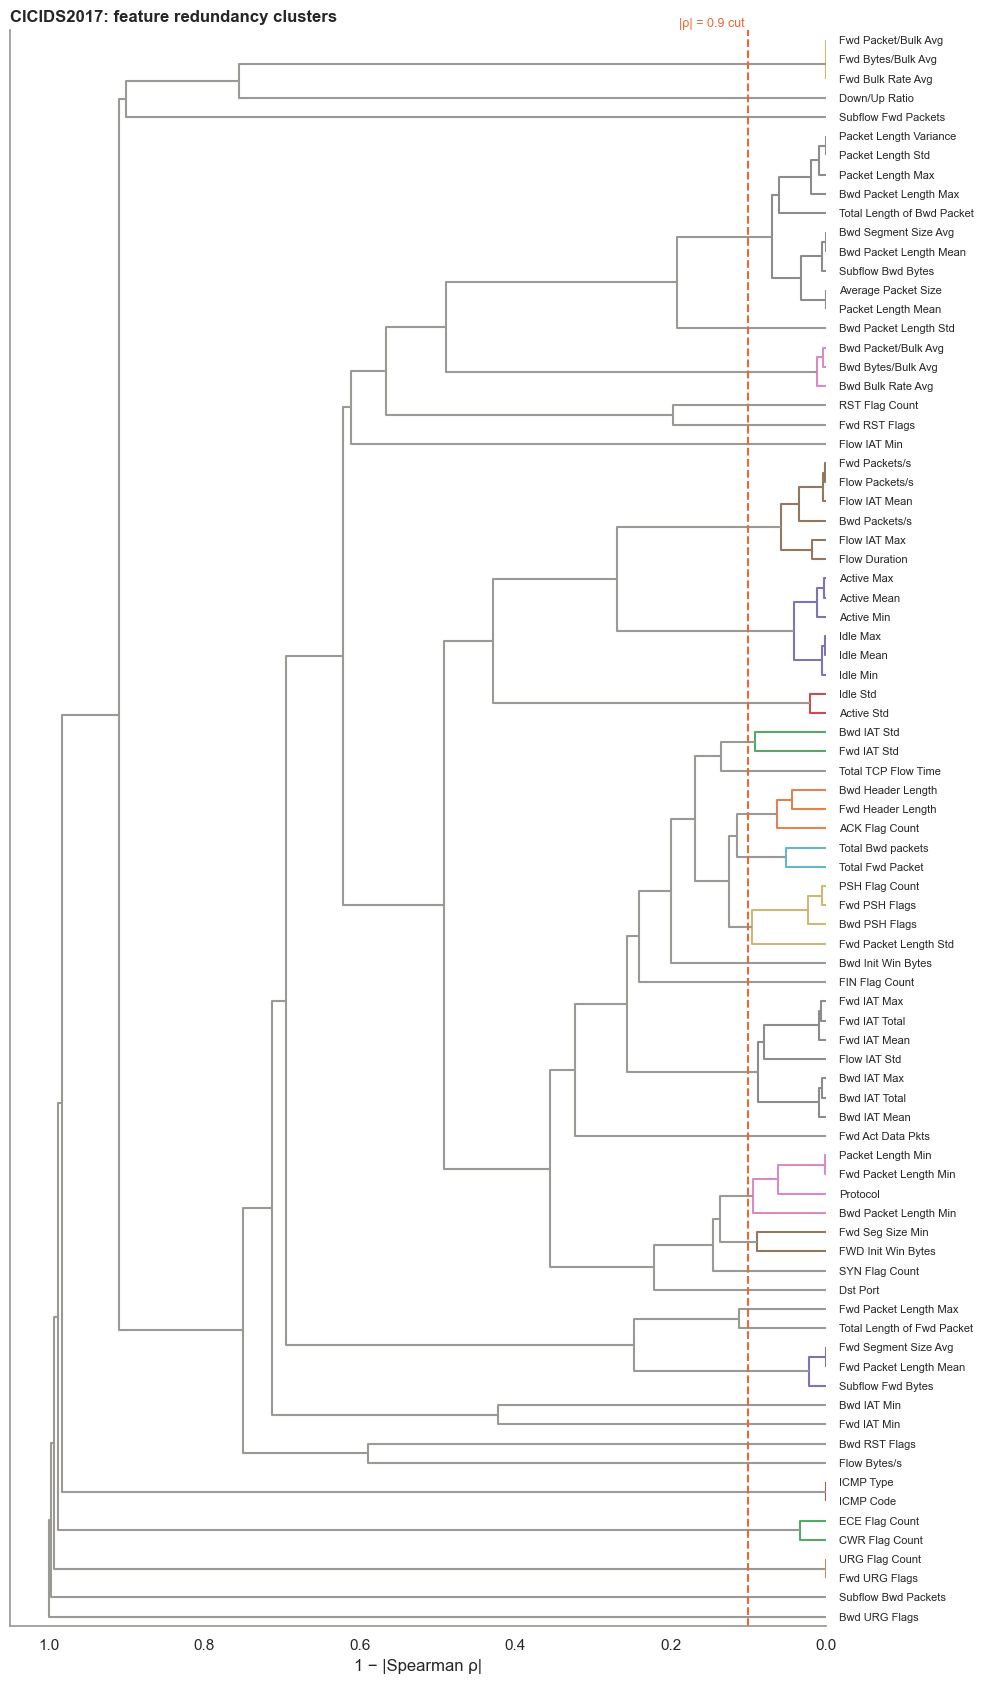

In [11]:
samp = d17[FEATURES].sample(100_000, random_state=SEED)
rho = samp.rank().corr().abs().fillna(0)
dist = 1 - rho.values; np.fill_diagonal(dist, 0); dist = (dist + dist.T) / 2
Z = linkage(squareform(dist, checks=False), method='average')

identical = [(a, b) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:] if samp[a].equals(samp[b])]
clusters = pd.Series({th: len(set(fcluster(Z, th, 'distance'))) for th in [0.0001, 0.05, 0.1, 0.2, 0.3]},
                     name='feature groups').rename_axis('distance threshold (1 − |ρ|)')
print(f'{len(identical)} pairs of features are exactly identical in the sample, e.g. {identical[:3]}')
display(clusters.to_frame())

fig, ax = plt.subplots(figsize=(10, 17))
dendrogram(Z, labels=FEATURES, orientation='left', color_threshold=0.1, above_threshold_color=GREY, leaf_font_size=8, ax=ax)
ax.axvline(0.1, color=ORANGE, lw=1.5, ls='--'); ax.text(0.1, ax.get_ylim()[1], '|ρ| = 0.9 cut ', color=ORANGE, fontsize=9, ha='right', va='bottom')
ax.set_xlabel('1 − |Spearman ρ|'); ax.set_title('CICIDS2017: feature redundancy clusters', loc='left')
ax.grid(False); plt.tight_layout(); plt.show()

In [12]:
groups = pd.Series(fcluster(Z, 0.1, 'distance'), index=FEATURES, name='group')
mean_ks = ks.mean()
reps = (pd.DataFrame({'group': groups, 'mean KS vs benign': mean_ks.round(3)})
          .sort_values('mean KS vs benign', ascending=False)
          .groupby('group').agg(representative=('mean KS vs benign', lambda s: s.index[0]),
                                members=('mean KS vs benign', 'size'),
                                rep_mean_KS=('mean KS vs benign', 'first'))
          .sort_values('rep_mean_KS', ascending=False))
print(f'{len(reps)} groups at |ρ| ≥ 0.9; one representative per group (highest mean KS):')
reps.reset_index(drop=True)

37 groups at |ρ| ≥ 0.9; one representative per group (highest mean KS):


,representative,members,rep_mean_KS
0,Bwd Segment Size Avg,10,0.882
1,Fwd Packet Length Max,1,0.788
2,Total Length of Fwd Packet,1,0.783
3,Subflow Fwd Bytes,3,0.764
4,Dst Port,1,0.758
5,Fwd Seg Size Min,2,0.744
6,Total TCP Flow Time,1,0.740
7,Flow Duration,6,0.735
8,Fwd PSH Flags,4,0.732
9,ACK Flag Count,3,0.730


### Q3 takeaway

**Q3 finding.** The 83 features collapse to 37 groups at |ρ| ≥ 0.9 and 22 groups at |ρ| ≥ 0.7. Six features are near-perfect copies of another feature (77 groups remain even at |ρ| ≥ 0.9999). One pair is exactly identical (`Fwd URG Flags` and `URG Flag Count`), and others differ only by rounding, such as `Fwd Packet Length Mean` and `Fwd Segment Size Avg`. Tree ensembles are largely unaffected by this redundancy, but it makes Logistic Regression coefficients and single-feature importance scores hard to interpret, because importance is split across copies. The 37 representatives above form a compact feature set to test in Module 24.


## Q4. Can a single feature identify an attack class, and is it a property of the attack or of the lab?

**Why we are doing this.** Shallow one-feature rules test whether high apparent separability comes from attack behavior or from environment variables such as ports and TCP settings.

**Business relevance.** A detector that identifies hosts or services instead of malicious behavior may fail after deployment. This analysis measures shortcut risk before model selection.

For each attack class, a depth-2 decision tree is trained on **one feature at a time** to separate that class from benign traffic. It uses up to 20,000 attack flows, 50,000 benign flows, and a 70/30 split. Its test F1 shows how much of the class can be identified by one rule on one column.

In the chart, a class with a single orange dot is one whose best feature is itself an environment feature.

The same test is repeated using only *environment* features: destination port, TCP initial window sizes, minimum segment size, and protocol. Their values are set by the lab's operating systems and service layout. A high environment-only score means a model can identify the class from the testbed rather than from attack behaviour.


,attack flows,best single feature,F1 (best feature),best environment feature,F1 (environment only)
class,,,,,
Web Attack - SQL Injection,13,Active Mean,0.400,Fwd Seg Size Min,0.000
DoS Slowhttptest,1740,Bwd Init Win Bytes,0.808,Bwd Init Win Bytes,0.808
DoS Slowloris,3859,Flow Duration,0.847,Bwd Init Win Bytes,0.702
Infiltration,36,Dst Port,0.917,Dst Port,0.917
DoS GoldenEye,7567,Bwd Packet Length Std,0.960,Bwd Init Win Bytes,0.951
Botnet,736,Dst Port,0.976,Dst Port,0.976
Web Attack - Brute Force,73,Bwd PSH Flags,0.977,Bwd Init Win Bytes,0.933
Infiltration - Portscan,20000,Total TCP Flow Time,0.980,FWD Init Win Bytes,0.980
Portscan,20000,Total TCP Flow Time,0.995,Dst Port,0.953


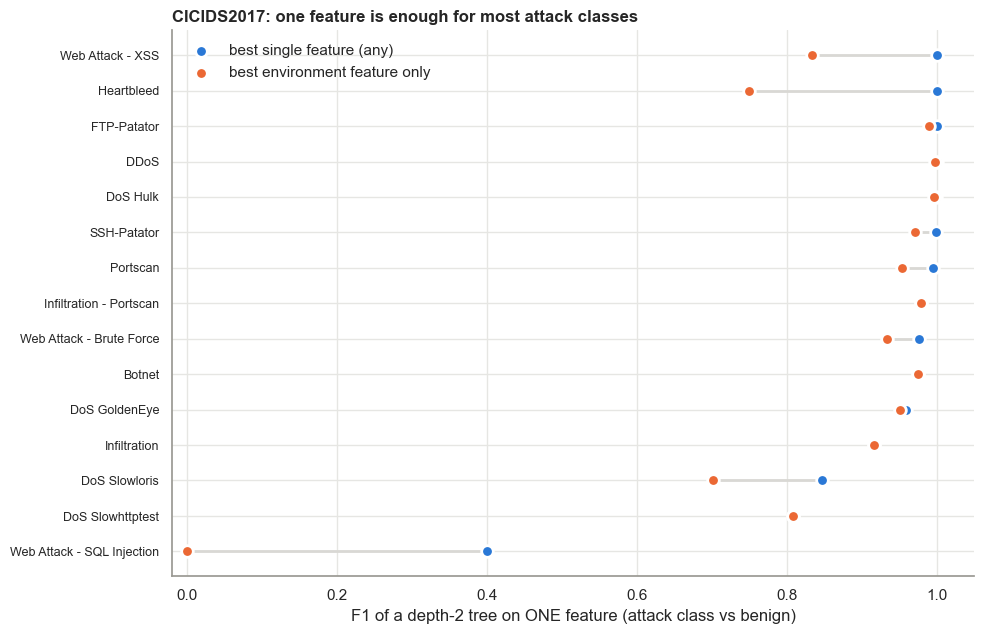

classes with single-feature F1 ≥ 0.95: 11 of 15
classes with environment-only F1 ≥ 0.90: ['Infiltration', 'DoS GoldenEye', 'Botnet', 'Web Attack - Brute Force', 'Infiltration - Portscan', 'Portscan', 'SSH-Patator', 'DoS Hulk', 'DDoS', 'FTP-Patator']


In [13]:
ben_q4 = d17.loc[d17['y'].eq('BENIGN'), FEATURES].sample(50_000, random_state=1)
rows = []
for c in attack_classes:
    a = d17.loc[d17['y'].eq(c), FEATURES]; a = a.sample(min(len(a), 20_000), random_state=1)
    Xc = pd.concat([ben_q4, a]); yc = np.r_[np.zeros(len(ben_q4)), np.ones(len(a))]
    tr, te, ytr, yte = train_test_split(Xc, yc, test_size=0.3, stratify=yc, random_state=SEED)
    score = {f: f1_score(yte, DecisionTreeClassifier(max_depth=2, random_state=SEED).fit(tr[[f]], ytr).predict(te[[f]]))
             for f in FEATURES}
    s = pd.Series(score).sort_values(ascending=False)
    env = s[s.index.isin(ENV_FEATURES)]
    rows.append({'class': c, 'attack flows': len(a), 'best single feature': s.index[0], 'F1 (best feature)': s.iloc[0],
                 'best environment feature': env.index[0], 'F1 (environment only)': env.iloc[0]})
q4 = pd.DataFrame(rows).set_index('class').sort_values('F1 (best feature)')
display(q4.round(3))

fig, ax = plt.subplots(figsize=(10, 6.5))
yy = np.arange(len(q4))
ax.hlines(yy, q4['F1 (environment only)'], q4['F1 (best feature)'], color='#d9d8d4', lw=2, zorder=1)
ax.scatter(q4['F1 (best feature)'], yy, s=70, color=BLUE, label='best single feature (any)', zorder=3, edgecolor='white', linewidth=2)
ax.scatter(q4['F1 (environment only)'], yy, s=70, color=ORANGE, label='best environment feature only', zorder=3, edgecolor='white', linewidth=2)
ax.set_yticks(yy); ax.set_yticklabels(q4.index, fontsize=9); ax.set_xlim(-0.02, 1.05)
ax.set_xlabel('F1 of a depth-2 tree on ONE feature (attack class vs benign)')
ax.set_title('CICIDS2017: one feature is enough for most attack classes', loc='left')
ax.legend(frameon=False, loc='upper left'); plt.tight_layout(); plt.show()

print('classes with single-feature F1 ≥ 0.95:', int((q4['F1 (best feature)'] >= 0.95).sum()), 'of', len(q4))
print('classes with environment-only F1 ≥ 0.90:', list(q4.index[q4['F1 (environment only)'] >= 0.90]))

### Q4 takeaway

**Q4 finding.** One threshold rule on one column separates 11 of the 15 attack classes from benign traffic with F1 ≥ 0.95, so very high scores on CICIDS2017 should be expected rather than celebrated. More importantly, **10 of 15 classes reach F1 ≥ 0.90 using only an environment feature**. Most often that feature is `Bwd Init Win Bytes`, the victim server's TCP window, which identifies *which server* was attacked. For Botnet and Infiltration it is the destination port, and for the internal port scan the attacker host's TCP window alone reaches 0.98. These are properties of this lab's hosts, not of the attacks, and a detector that relies on them would not transfer to another network. Module 24 should measure permutation importance and retrain without these columns to quantify how much performance depends on them.


## Q5. How much does a random split leak near-duplicate flows into the test set?

**Why we are doing this.** Near-duplicate exposure is compared under random and chronological splits to quantify how often test flows resemble training flows from the same burst.

**Business relevance.** Leakage inflates benchmark scores and can lead to unsafe deployment decisions. The result determines which evaluation design should be treated as the headline result.

Attacks are run as scripted bursts, so many flows from one burst are almost identical. Each flow's model features are signed-log transformed, rounded to approximately 10% bins, and hashed. A test flow is counted as a near-duplicate when a training flow has the same fingerprint and label.

This notebook compares a stratified random 80/20 split with a within-class chronological split using the latest 20% as test data. Model-score comparisons are left to the modeling notebooks.


In [14]:
def fingerprint(X, scale=10):
    h = np.zeros(len(X), np.uint64)
    for c in X.columns:
        q = np.round(signed_log(X[c].values.astype('float64')) * scale).astype(np.int64).view(np.uint64)
        h = (h * np.uint64(1099511628211)) ^ q
    return h

yv = d17['y'].values
rng = np.random.default_rng(SEED)
test_random = np.zeros(len(d17), bool)
for c in np.unique(yv):
    idx = np.where(yv == c)[0]; test_random[rng.choice(idx, int(round(0.2 * len(idx))), replace=False)] = True
test_time = np.zeros(len(d17), bool)
for c, g in d17[['y', 'ts', 'id']].groupby('y'):
    g = g.sort_values(['ts', 'id']); test_time[g.index[-int(round(0.2 * len(g))):]] = True

fp = fingerprint(d17[FEATURES])
def near_dup_rate(test_mask):
    train = pd.DataFrame({'h': fp[~test_mask], 'y': yv[~test_mask]}).drop_duplicates().assign(hit=1)
    test = pd.DataFrame({'h': fp[test_mask], 'y': yv[test_mask]})
    hit = test.merge(train, on=['h', 'y'], how='left')['hit'].notna().values
    return pd.Series(hit).groupby(test['y'].values).mean(), hit.mean(), test['y'].value_counts()

r_cls, r_all, n_test = near_dup_rate(test_random)
t_cls, t_all, _ = near_dup_rate(test_time)
q5 = pd.DataFrame({'test flows': n_test, 'near-dup share, random split': r_cls, 'near-dup share, time split': t_cls})
q5['change (pp)'] = (q5['near-dup share, time split'] - q5['near-dup share, random split']) * 100
print(f'Overall near-duplicate share of the test set: random {r_all:.1%} | time-ordered {t_all:.1%}')
q5.sort_values('change (pp)').round(3)

Overall near-duplicate share of the test set: random 38.7% | time-ordered 38.6%


,test flows,"near-dup share, random split","near-dup share, time split",change (pp)
DoS Slowhttptest,348,0.422,0.032,-39.080
DoS Slowloris,772,0.374,0.140,-23.446
SSH-Patator,592,0.216,0.144,-7.264
Botnet,147,0.129,0.082,-4.762
DDoS,19029,0.043,0.019,-2.423
Infiltration - Portscan,8236,0.678,0.654,-2.404
DoS Hulk,31694,0.141,0.126,-1.533
Portscan,18124,0.953,0.948,-0.546
Heartbleed,2,0.000,0.000,0.000
Infiltration,7,0.000,0.000,0.000


### Q5 takeaway

**Q5 finding.** Overall near-duplicate exposure is similar because repetitive benign and port-scan traffic dominates both splits. The class-level result is more informative: DoS Slowhttptest falls from approximately 39% near-duplicate exposure under the random split to 3% under the chronological split, while DoS Slowloris falls from approximately 36% to 14%. A random split therefore makes some attack classes easier by placing highly similar burst traffic in training and testing. Chronological evaluation should be the headline design.


## Q6. Do the same attack families look the same in 2017 and 2018?

**Why we are doing this.** Compatible attack families are compared across 2017 and 2018 to measure whether their feature distributions remain stable in another capture environment.

**Business relevance.** Distribution drift is the central deployment risk in this project. It explains why strong within-year metrics may not translate into cross-network recall or acceptable false-alarm rates.

Labels are aligned with the family mapping in [`ATTACK_LABELS.md`](../docs/ATTACK_LABELS.md) §4. Only attack labels present in both years, with at least 30 effective flows in the 2018 sample, are compared. For each family and feature, the KS statistic compares the 2017 distribution with the 2018 distribution. Values near 0 mean the family looks the same in both years; values near 1 mean it looks completely different.


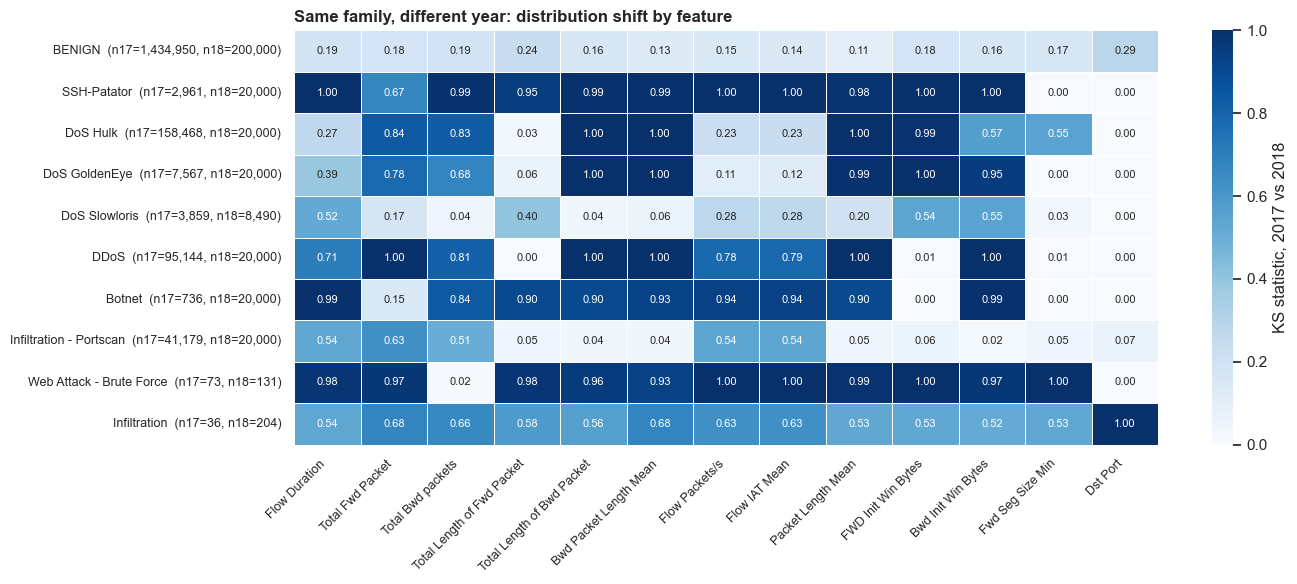

,mean KS across features
BENIGN,0.175
DoS Slowloris,0.240
Infiltration - Portscan,0.240
DoS GoldenEye,0.545
DoS Hulk,0.580
Infiltration,0.621
DDoS,0.623
Botnet,0.654
SSH-Patator,0.813
Web Attack - Brute Force,0.830


In [15]:
MAP18 = {'BENIGN': 'BENIGN', 'SSH-BruteForce': 'SSH-Patator', 'DoS Hulk': 'DoS Hulk', 'DoS GoldenEye': 'DoS GoldenEye',
         'DoS Slowloris': 'DoS Slowloris', 'DDoS-LOIC-HTTP': 'DDoS', 'Botnet Ares': 'Botnet',
         'Infiltration - NMAP Portscan': 'Infiltration - Portscan', 'Web Attack - Brute Force': 'Web Attack - Brute Force',
         'Web Attack - XSS': 'Web Attack - XSS', 'Web Attack - SQL': 'Web Attack - SQL Injection',
         'Infiltration - Communication Victim Attacker': 'Infiltration'}
s18['family'] = s18['Label'].map(MAP18)
shared = [f for f in MAP18.values() if (s18['family'] == f).sum() >= 30 and (d17['y'] == f).sum() >= 30]
drift_feats = ['Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet',
               'Bwd Packet Length Mean', 'Flow Packets/s', 'Flow IAT Mean', 'Packet Length Mean',
               'FWD Init Win Bytes', 'Bwd Init Win Bytes', 'Fwd Seg Size Min', 'Dst Port']
drift = {}
for fam in shared:
    a = d17.loc[d17['y'].eq(fam), drift_feats]; a = a.sample(min(len(a), 20_000), random_state=SEED)
    b = s18.loc[s18['family'].eq(fam), drift_feats]
    drift[fam] = {f: ks_2samp(a[f], b[f]).statistic for f in drift_feats}
drift = pd.DataFrame(drift).T
drift['n 2017'] = [int((d17['y'] == f).sum()) for f in drift.index]
drift['n 2018 sample'] = [int((s18['family'] == f).sum()) for f in drift.index]

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(drift[drift_feats], cmap=SEQ, vmin=0, vmax=1, annot=True, fmt='.2f', annot_kws={'fontsize': 8},
            linewidths=0.5, linecolor='white', cbar_kws={'label': 'KS statistic, 2017 vs 2018'}, ax=ax)
ax.set_yticklabels([f'{f}  (n17={drift.loc[f, "n 2017"]:,}, n18={drift.loc[f, "n 2018 sample"]:,})' for f in drift.index], fontsize=9, rotation=0)
ax.set_title('Same family, different year: distribution shift by feature', loc='left'); ax.set_xlabel(''); ax.set_ylabel('')
plt.xticks(rotation=45, ha='right', fontsize=9); plt.tight_layout(); plt.show()
drift[drift_feats].mean(axis=1).sort_values().rename('mean KS across features').round(3).to_frame()

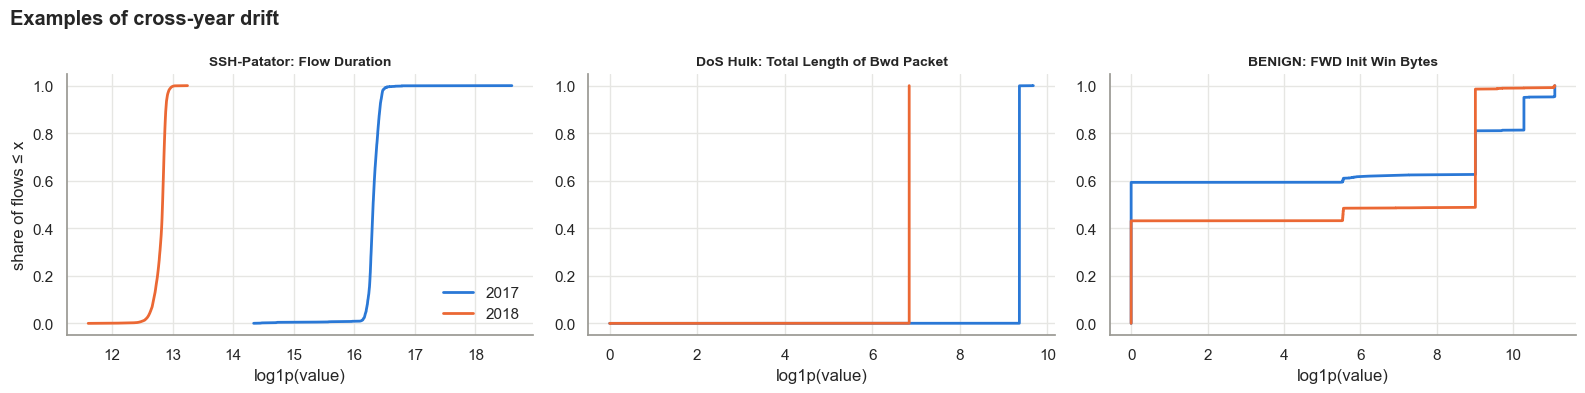

In [16]:
examples = [('SSH-Patator', 'Flow Duration'), ('DoS Hulk', 'Total Length of Bwd Packet'), ('BENIGN', 'FWD Init Win Bytes')]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (fam, f) in zip(axes, examples):
    for vals, col, lab in [(d17.loc[d17['y'].eq(fam), f], BLUE, '2017'), (s18.loc[s18['family'].eq(fam), f], ORANGE, '2018')]:
        v = np.sort(signed_log(vals.sample(min(len(vals), 20_000), random_state=SEED).values))
        ax.plot(v, np.arange(1, len(v) + 1) / len(v), lw=2, color=col, label=lab)
    ax.set_title(f'{fam}: {f}', fontsize=10); ax.set_xlabel('log1p(value)')
axes[0].set_ylabel('share of flows ≤ x'); axes[0].legend(frameon=False, loc='lower right')
fig.suptitle('Examples of cross-year drift', fontweight='bold', x=0.01, ha='left')
plt.tight_layout(); plt.show()

### Q6 takeaway

**Q6 finding.** Benign traffic shifts only moderately between years: KS values are 0.11–0.29. Attack families shift much more, even when the same tool was used:

- **SSH brute force** keeps its destination port and similar packet sizes, but nearly every timing and size feature has KS ≈ 1, because the 2018 runs are about 30 times shorter.
- **DoS Hulk** and **DoS GoldenEye** send the same forward requests (KS on forward bytes ≤ 0.06), but the server's response sizes have KS = 1.00 because the victim web page changed.
- **DDoS (LOIC-HTTP)** changes on duration, packet counts, and server response, but keeps the attacker's TCP window.
- **DoS Slowloris** and **Infiltration – Portscan** are the most stable attack families.

Destination port is stable for every family except Infiltration, which is one more reason a model may lean on it. Families whose distinguishing features drifted should lose recall when a 2017 model is applied to 2018.
